### <b>9차시 히트맵과 다중 그래프 - heatmap · pivot_table · FacetGrid · pairplot</b>

* <b>corr()</b>로 여러 열의 상관계수를 표 하나로 구하고, <b>heatmap</b>으로 칸마다 색을 칠해 한눈에 훑는다. 양·음이 있는 값은 가운데가 연한 <b>발산형 색</b>, 한쪽으로만 커지는 값은 <b>연속형 색</b>을 쓴다.
* <b>pivot_table</b>로 월×요일처럼 두 범주가 만나는 표를 만들고, 그 표를 히트맵으로 그린다.
* <b>relplot</b>·<b>catplot</b>·<b>pairplot</b>은 8차시 lmplot처럼 칸을 스스로 만드는 함수다. 같은 그래프를 집단별로 쪼개 나란히 놓거나, 여러 변수 쌍을 한 장에 모은다. 많이 보여 줄수록 색과 배치의 규칙이 중요해진다.

* 맨 위 코드 셀은 <b>준비 셀</b>이다. 한글 폰트를 설치해 등록하고, 실습 데이터를 <b>data</b> 폴더에 내려받는다.
  * 내용은 고치지 않고 실행만 한다. 출력에 CSV 파일 이름 두 개가 보이면 끝난 것이다.
  * 세션이 끊겨도 입력한 코드는 남아 있다. 이어서 할 셀을 선택하고 <b>런타임 › 이전 셀 실행</b>을 누르면 준비 셀부터 다시 실행된다.
* 나머지 코드 칸은 강의를 따라 입력한다. 주석(#)은 입력하지 않아도 되고, 앞 셀과 비슷한 코드는 복사해 고친다.

In [1]:
# keep
# 나눔고딕 폰트를 설치한다
!apt-get -qq install -y fonts-nanum > /dev/null
# 실습 데이터를 data 폴더에 내려받는다
!mkdir -p data
!wget -q -nc -P data https://raw.githubusercontent.com/wonguwon/generate_lesson/feature/lesson-subagents/materials/matplotlib-seaborn/data/students.csv https://raw.githubusercontent.com/wonguwon/generate_lesson/feature/lesson-subagents/materials/matplotlib-seaborn/data/cafe_sales.csv
# 설치한 폰트를 Matplotlib에 등록한다
from matplotlib import font_manager
font_manager.fontManager.addfont('/usr/share/fonts/truetype/nanum/NanumGothic.ttf')
# 내려받은 파일을 확인한다
!ls data

* 준비 셀 다음 셀에 6차시에서 정한 <b>설정 셀</b>을 그대로 입력한다.
  * <b>sns.set_theme(...)</b>에 한글 폰트와 마이너스 설정을 함께 넘긴다. <b>sns.set_theme()</b>을 인자 없이 불러 글자가 깨지면 이 셀을 다시 실행한다. 세션을 다시 시작했다면 준비 셀부터 실행한다.

In [2]:
# 표는 pandas, 그래프는 plt와 Seaborn으로 다룬다
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 테마와 한글 폰트를 함께 정한다
sns.set_theme(style='whitegrid', font='NanumGothic', rc={'axes.unicode_minus': False})

* 오늘은 두 파일을 모두 쓴다. 2차시와 같은 방법으로 읽는다. <b>data</b> 폴더는 준비 셀이 Colab에 내려받은 폴더다.
  * <b>students</b>: 학생 300명의 생활 습관 설문(가상), 학생 1명 = 1행
  * <b>cafe</b>: 캠퍼스 카페 1년 일별 판매(가상), 하루 = 1행
* 전공·요일 순서 리스트도 7차시와 같이 미리 만들어 둔다.

In [3]:
# 학생 설문 CSV를 읽어 students에 담는다
students = pd.read_csv('data/students.csv')
# 카페 판매 CSV를 date 열은 날짜로 읽어 cafe에 담는다
cafe = pd.read_csv('data/cafe_sales.csv', parse_dates=['date'])
# 두 표의 행과 열 수를 출력한다
print(students.shape, cafe.shape)

# 전공 순서 리스트
major_order = ['공학', '자연과학', '사회과학', '인문', '예체능']
# 요일 순서 리스트
weekday_order = ['월', '화', '수', '목', '금', '토', '일']

(300, 12) (365, 14)


#### <b>1) 학생 데이터 상관 히트맵</b>

* 8차시에서는 <b>열1.corr(열2)</b>로 두 열의 상관계수를 한 쌍씩 구했다. 열이 많으면 쌍이 너무 많아진다.
* <b>표.corr()</b>: 표의 모든 수치 열 쌍의 상관계수를 한 번에 구해 표(<b>상관행렬</b>)로 돌려준다.
  * 그런데 students에는 student_id·major·housing 같은 글자 열이 있다. 그냥 <b>students.corr()</b>를 실행하면 글자를 숫자로 바꾸지 못해 <b>ValueError: could not convert string to float: 'S001'</b> 오류가 난다.
  * <b>numeric_only=True</b>: 수치 열만 골라 계산한다.
* 수치 열만 고르는 다른 방법으로 <b>select_dtypes('number')</b>가 있다. 어떤 열이 남는지 먼저 확인한다.
  * <b>tolist()</b>: 결과를 리스트로 바꾼다.

In [4]:
# 수치 열만 골라 열 이름을 리스트로 꺼낸다
students.select_dtypes('number').columns.tolist()

['grade',
 'commute_minutes',
 'study_hours',
 'sleep_hours',
 'sns_minutes',
 'part_time_hours',
 'coffee_cups',
 'exam_score',
 'gpa']

* 수치 열은 9개다. grade(학년)도 숫자라서 들어간다.
* 상관행렬을 만든다. 8차시처럼 <b>round(2)</b>로 소수 둘째 자리까지 반올림한다.

In [5]:
# 수치 열의 상관행렬을 구해 student_corr에 담는다
student_corr = students.corr(numeric_only=True).round(2)
# 상관행렬을 본다
student_corr

,grade,commute_minutes,study_hours,sleep_hours,sns_minutes,part_time_hours,coffee_cups,exam_score,gpa
grade,1.00,0.13,-0.02,-0.09,0.05,0.06,0.05,0.02,0.08
commute_minutes,0.13,1.00,-0.00,-0.06,0.04,-0.09,-0.05,-0.06,-0.10
study_hours,-0.02,-0.00,1.00,0.00,-0.03,-0.28,0.15,0.65,0.45
sleep_hours,-0.09,-0.06,0.00,1.00,-0.36,0.12,-0.20,-0.07,-0.12
sns_minutes,0.05,0.04,-0.03,-0.36,1.00,0.12,0.02,0.06,0.05
part_time_hours,0.06,-0.09,-0.28,0.12,0.12,1.00,-0.08,-0.16,-0.04
coffee_cups,0.05,-0.05,0.15,-0.20,0.02,-0.08,1.00,0.08,0.02
exam_score,0.02,-0.06,0.65,-0.07,0.06,-0.16,0.08,1.00,0.72
gpa,0.08,-0.10,0.45,-0.12,0.05,-0.04,0.02,0.72,1.00


* 표 읽는 법
  * 행과 열이 만나는 칸이 두 열의 r이다. 8차시에서 구한 값이 그대로 들어 있다(study_hours-exam_score 0.65, exam_score-gpa 0.72, sleep_hours-sns_minutes -0.36, study_hours-part_time_hours -0.28).
  * 대각선은 자기 자신과의 상관이라 모두 1.00이다.
  * 대각선을 기준으로 위아래가 똑같다(study_hours-gpa와 gpa-study_hours는 같은 값).
* 9×9 = 81칸의 숫자를 눈으로 훑기는 어렵다. <b>sns.heatmap(표)</b>: 표의 칸마다 값에 맞는 색을 칠한다.
  * <b>annot=True</b>: 칸 안에 숫자를 쓴다. <b>fmt='.2f'</b>: 소수 둘째 자리까지 쓴다.
  * heatmap은 scatterplot처럼 Axes에 그리는 함수라서 <b>ax=</b>로 칸을 정한다.
* 먼저 색 설정 없이 그려 본다.

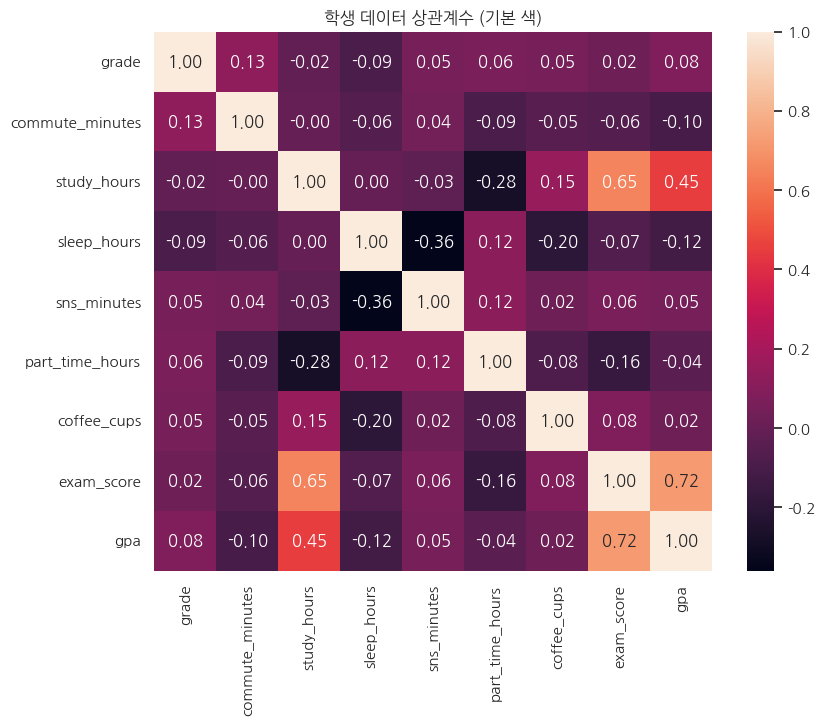

In [6]:
# 그래프를 그릴 칸을 만든다
fig, ax = plt.subplots(figsize=(9, 7))
# 기본 색으로 히트맵을 그리고 칸에 숫자를 쓴다
sns.heatmap(student_corr, annot=True, fmt='.2f', ax=ax)
# 제목을 단다
ax.set_title('학생 데이터 상관계수 (기본 색)')
# 그래프를 화면에 보여 준다
plt.show()

* 기본 색은 값이 작을수록 어둡고 클수록 밝다. 그런데 이 색으로는 읽기 어렵다.
  * 가장 어두운 칸은 표에서 가장 작은 값 -0.36이고, 가장 밝은 칸은 대각선 1.00이다. 색의 양 끝이 데이터에 맞춰 정해져서, 0이 어디쯤인지(양인지 음인지) 색만으로 알 수 없다.
* 상관계수는 <b>-1~1</b>이고 <b>0이 가운데</b>다. 이런 값에는 가운데가 연하고 양쪽으로 다른 색이 진해지는 <b>발산형(diverging) 색</b>을 쓴다.
  * <b>cmap='coolwarm'</b>: 음수는 파랑, 양수는 빨강, 0 근처는 연한 회색이다.
  * <b>vmin=-1, vmax=1</b>: 색의 양 끝을 -1과 1로 고정한다. 데이터가 바뀌어도 같은 색이 같은 값을 뜻한다.
  * <b>center=0</b>: 0을 가운데 색에 맞춘다.

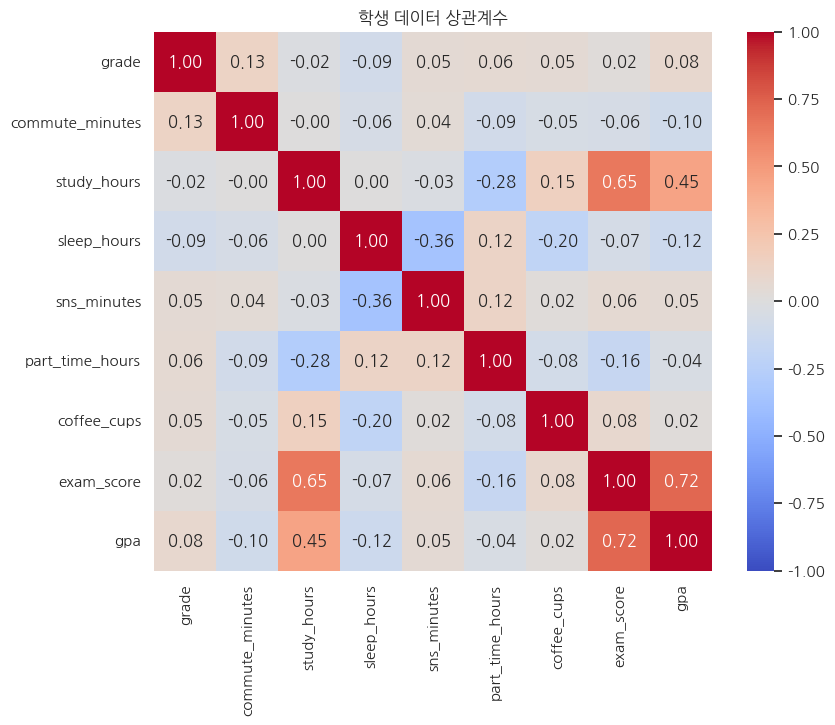

In [7]:
# 그래프를 그릴 칸을 만든다
fig, ax = plt.subplots(figsize=(9, 7))
# 발산형 색으로 그리고 색 범위를 -1~1로 고정한다
sns.heatmap(student_corr, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1, center=0, ax=ax)
# 제목을 단다
ax.set_title('학생 데이터 상관계수')
# 그래프를 화면에 보여 준다
plt.show()

* 그래프에서 읽을 것
  * 대각선을 빼면 가장 진한 빨강은 exam_score-gpa(0.72), 그다음 study_hours-exam_score(0.65), study_hours-gpa(0.45)다. 공부·점수·평점이 서로 함께 움직인다.
  * 가장 진한 파랑은 sleep_hours-sns_minutes(-0.36), 그다음 study_hours-part_time_hours(-0.28)다.
  * grade·commute_minutes 줄은 거의 연한 회색이다(모두 -0.10~0.13). 학년·통학 시간은 다른 열과 직선 관계가 거의 없다.
* 히트맵은 "어디를 더 볼지" 고르는 지도다. 진한 칸을 찾으면 8차시처럼 그 두 열의 산점도로 모양을 확인한다. r은 직선 관계만 잰다.

#### <b>2) 월×요일 평균 손님 수 히트맵</b>

* 히트맵은 상관행렬이 아니어도 <b>행과 열이 있는 표</b>면 무엇이든 그린다.
* 2차시의 groupby는 한 방향(월별, 요일별)으로 묶었다. <b>월과 요일 두 방향</b>으로 묶으면 "2025-03의 월요일 평균" 같은 칸이 생긴다.
* <b>표.pivot_table(index='행', columns='열', values='값', aggfunc='mean')</b>
  * <b>index</b>: 행으로 놓을 열(year_month), <b>columns</b>: 열로 펼칠 열(weekday)
  * <b>values</b>: 칸에 넣을 값(customers), <b>aggfunc</b>: 묶은 값을 하나로 줄이는 방법. 'mean'(평균)이 기본값이고, 'sum'·'count'도 쓸 수 있다.

In [8]:
# 월×요일 평균 손님 수 표를 만든다
customers_pivot = cafe.pivot_table(index='year_month', columns='weekday', values='customers', aggfunc='mean')
# 열 이름을 리스트로 꺼내 순서를 본다
customers_pivot.columns.tolist()

['금', '목', '수', '월', '일', '토', '화']

* 행(year_month)은 '2025-03' 같은 글자라 정렬해도 2025-03 → 2026-02 순서가 맞다(3차시).
* 열(요일)은 groupby처럼 가나다순(금·목·수·월·일·토·화)이다. 2차시의 <b>reindex</b>로 순서를 맞춘다.
  * 열 순서를 바꿀 때는 <b>reindex(columns=순서 리스트)</b>처럼 columns=를 붙인다.

In [9]:
# 열을 월~일 순서로 맞추고 반올림한다
customers_pivot = customers_pivot.reindex(columns=weekday_order).round(2)
# 순서를 맞춘 표를 본다
customers_pivot

weekday,월,화,수,목,금,토,일
year_month,,,,,,,
2025-03,446.20,438.50,528.00,407.75,349.50,165.80,141.80
2025-04,487.25,504.40,506.40,416.75,354.25,190.75,147.75
2025-05,399.00,444.00,495.25,384.00,345.60,164.00,145.50
2025-06,369.20,466.00,484.75,378.00,324.00,150.75,127.00
2025-07,176.50,183.80,209.60,170.80,145.50,89.00,75.00
2025-08,177.50,194.50,205.00,167.00,143.00,92.60,76.40
2025-09,435.00,436.20,469.00,374.75,319.25,161.00,130.50
2025-10,339.25,353.50,397.60,396.40,342.60,173.75,111.00
2025-11,372.75,451.50,439.50,389.75,332.25,160.40,134.80


* 12행 × 7열 표다. 칸 하나는 그 달 그 요일(4~5일)의 평균 손님 수다. 휴무일 0도 그대로 평균에 들어간다(2차시).
* 7차시의 <b>groupby(두 열) + unstack()</b>으로도 같은 표가 나온다. 확인해 본다.
  * 칸별로 비교한 뒤 <b>all()</b>을 두 번 써서 표 전체가 같은지 본다.

In [10]:
# groupby와 unstack으로 같은 표를 만든다
same = cafe.groupby(['year_month', 'weekday'])['customers'].mean().unstack().reindex(columns=weekday_order).round(2)
# 두 표의 모든 칸이 같은지 확인한다
print((same == customers_pivot).all().all())

True


* True: 모든 칸이 같다. pivot_table은 이 두 단계를 한 번에 해 준다.
* 이 표를 히트맵으로 그린다. 손님 수는 0에서 한쪽으로만 커지는 값이다. 이런 값에는 연한 색에서 진한 색으로 가는 <b>연속형(sequential) 색</b>을 쓴다.
  * <b>cmap='YlOrRd'</b>: 노랑(적음) → 주황 → 빨강(많음)
  * <b>fmt='.0f'</b>: 칸이 작아 정수로만 쓴다.
  * <b>cbar_kws={'label': '…'}</b>: 오른쪽 색 막대(colorbar)에 이름을 단다.

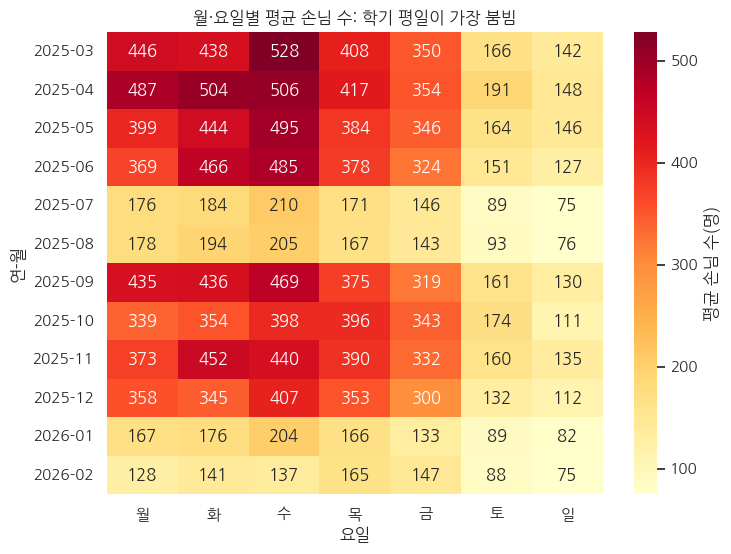

In [11]:
# 그래프를 그릴 칸을 만든다
fig, ax = plt.subplots(figsize=(8, 6))
# 연속형 색으로 그리고 색 막대에 이름을 단다
sns.heatmap(customers_pivot, annot=True, fmt='.0f', cmap='YlOrRd',
            cbar_kws={'label': '평균 손님 수(명)'}, ax=ax)
# 제목과 축 이름을 단다
ax.set_title('월·요일별 평균 손님 수: 학기 평일이 가장 붐빔')
ax.set_xlabel('요일')
ax.set_ylabel('연-월')
# 그래프를 화면에 보여 준다
plt.show()

* 그래프에서 읽을 것
  * 진한 칸은 학기 달(3~6월, 9~12월)의 월~목에 모여 있다. 가장 진한 칸은 2025-03 수요일(528명)이다.
  * 토·일 열은 모든 달에 연하고, 방학 달(7·8월, 1·2월) 행은 모든 요일이 연하다. 가장 연한 곳은 방학 달 일요일(75~82명)이다.
  * 2025-10의 월(339)·수(398)는 학기 달의 같은 요일 가운데 가장 연하다. 추석 휴무일(10/5~10/8, 그중 월~수는 10/6~10/8)의 0이 평균에 들어갔다.
  * 2026-02는 목(165)이 월~수(128·141·137)보다 진하다. 설 휴무일(2/16~2/18, 월~수)의 0 때문이다.
* 3차시 선 그래프는 월별 흐름, 7차시 pointplot은 요일별 차이를 따로 보여 줬다. 피벗 히트맵은 두 가지를 한 장에 담는다.

#### <b>3) 주거 형태별로 나눈 공부 시간-점수 산점도</b>

* 8차시의 <b>lmplot</b>은 Figure와 칸을 스스로 만들고 <b>FacetGrid</b>(칸 묶음)를 돌려줬다. 이런 함수를 <b>figure 수준 함수</b>라고 한다.
* Seaborn에는 figure 수준 함수가 더 있다. 지금까지 쓴 axes 수준 함수를 묶어서 칸 나누기를 더한 것이다.
  * <b>relplot</b>: 관계 그래프. <b>kind='scatter'</b>(scatterplot, 기본값) 또는 <b>kind='line'</b>(lineplot)
  * <b>catplot</b>: 범주 그래프. <b>kind='strip'</b>(기본값)·'box'·'violin'·'bar'·'count'·'point'
* 칸 나누기 인자
  * <b>col=</b>: 값마다 칸을 옆으로, <b>row=</b>: 값마다 칸을 아래로 늘어놓는다.
  * <b>col_wrap=</b>: 한 줄에 놓을 칸 수. 넘치면 다음 줄로 넘긴다.
* 5차시에서 subplots로 칸을 만들고 칸마다 그리던 일을 열 이름 하나로 해 준다.
* 주거 형태(housing)마다 공부 시간-점수 산점도를 칸 하나씩 그린다. 칸 제목·축 이름은 8차시 lmplot과 같은 방법으로 단다.

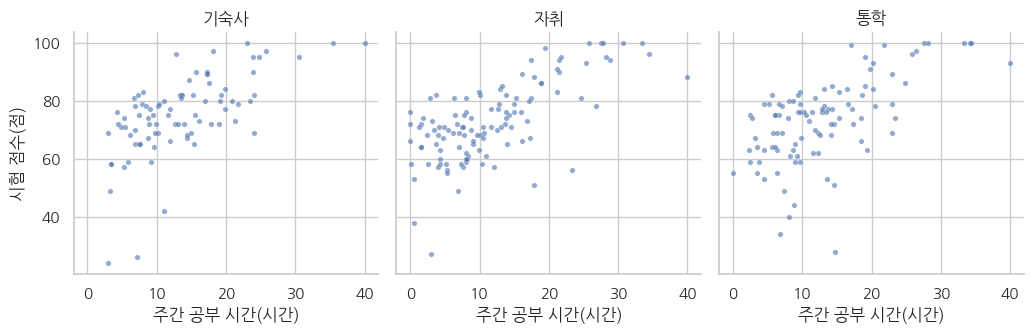

<class 'seaborn.axisgrid.FacetGrid'>


In [12]:
# 주거 형태마다 칸을 나눠 산점도를 그린다
g = sns.relplot(data=students, x='study_hours', y='exam_score', col='housing', kind='scatter',
                height=3.5, s=15, alpha=0.6)
# 칸 제목을 주거 형태 이름으로 단다
g.set_titles('{col_name}')
# 모든 칸의 축 이름을 단다
g.set_axis_labels('주간 공부 시간(시간)', '시험 점수(점)')
# 그래프를 화면에 보여 준다
plt.show()

# g의 종류를 출력한다
print(type(g))

* 칸 세 개가 기숙사·자취·통학 순서(표에 처음 나온 순서)로 놓인다. 순서를 바꾸려면 <b>col_order=</b>를 준다.
* 세 칸 모두 점 무리가 오른쪽 위로 기운다. 자취 칸이 학생이 가장 많아(115명) 점이 가장 많다.
* x·y축 눈금이 세 칸에 같다(공유). 그래서 칸끼리 높이·퍼짐을 바로 비교할 수 있다.
* 주거 형태가 달라도 관계 모양은 비슷하다. 숫자로 확인한다.

In [13]:
# 주거 형태를 차례로 돈다
for housing in ['기숙사', '자취', '통학']:
    # 그 주거 형태의 학생만 고른다
    part = students[students['housing'] == housing]
    # 주거 형태, 학생 수, 상관계수를 출력한다
    print(housing, len(part), round(part['study_hours'].corr(part['exam_score']), 2))

기숙사 85 0.63
자취 115 0.68
통학 100 0.62


* 기숙사 0.63, 자취 0.68, 통학 0.62로 비슷하다. 칸을 나눠 봤더니 차이가 없다는 것도 하나의 답이다.

* 이번에는 <b>catplot</b>으로 박스플롯을 학년별 칸에 나눠 그린다(6차시 boxplot).
  * <b>kind='box'</b>: boxplot으로 그린다. <b>order=major_order</b>로 칸 안의 상자 순서를 정한다.
  * <b>col='grade', col_wrap=2</b>: 학년 1~4를 2칸씩 두 줄(2×2)로 놓는다.
  * <b>aspect</b>: 칸의 가로 ÷ 세로(8차시). 전공 이름 다섯 개가 겹치지 않게 가로를 넓힌다.
  * <b>g.set_titles('{col_name}학년')</b>: {col_name} 자리에 1·2·3·4가 들어간다.

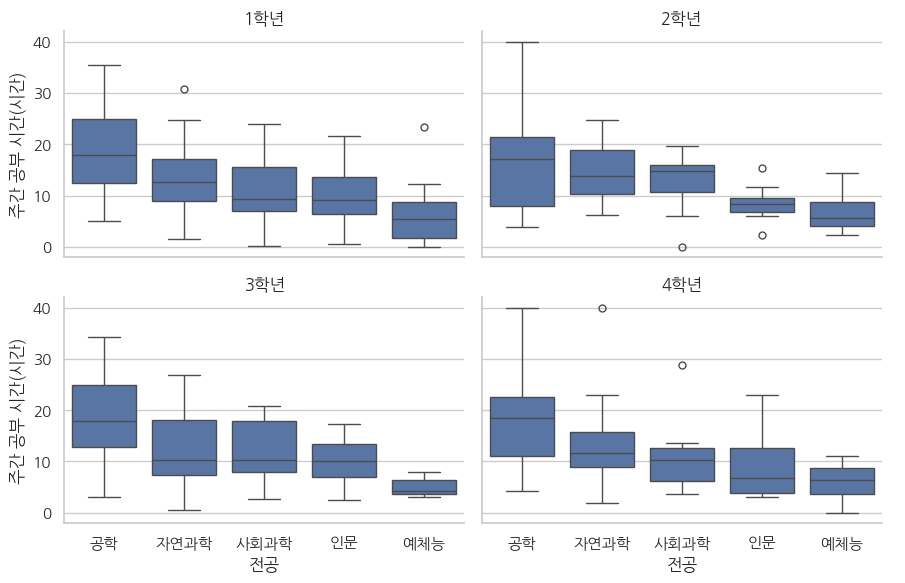

In [14]:
# 학년마다 칸을 나눠 박스플롯을 그린다
g = sns.catplot(data=students, x='major', y='study_hours', col='grade', col_wrap=2, kind='box',
                order=major_order, height=3, aspect=1.5)
# 칸 제목을 '1학년' 꼴로 단다
g.set_titles('{col_name}학년')
# 모든 칸의 축 이름을 단다
g.set_axis_labels('전공', '주간 공부 시간(시간)')
# 그래프를 화면에 보여 준다
plt.show()

* 네 칸 모두 공학 상자가 가장 높고 예체능 상자가 가장 낮다. 학년이 달라도 전공별 순서가 크게 바뀌지 않는다.
* col_wrap을 쓰면 칸이 한 줄로 늘어선 배열이 되어 <b>g.axes[i]</b>로 칸을 꺼낸다(8차시의 g.axes[0, i]와 다름).

* 참고: figure 수준 함수가 안에서 하는 일을 직접 할 수도 있다.
  * <b>sns.FacetGrid(표, row='열')</b>로 빈 칸 묶음을 만들고, <b>g.map_dataframe(그릴 함수, x='열')</b>로 칸마다 그 함수를 실행한다.
  * relplot·catplot에 없는 그래프(예: histplot)를 칸마다 그릴 때 쓴다. histplot은 figure 수준 displot(col=·row=)도 있다.
* 분포를 비교할 때는 <b>row=</b>로 칸을 위아래로 쌓으면 x축이 한 줄로 맞아 비교하기 쉽다.

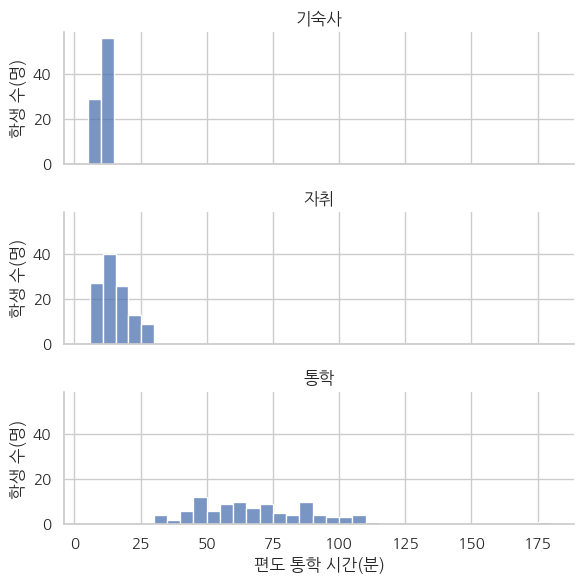

In [15]:
# 주거 형태마다 위아래로 빈 칸을 만든다
g = sns.FacetGrid(students, row='housing', height=2, aspect=3)
# 칸마다 통학 시간 히스토그램을 그린다
g.map_dataframe(sns.histplot, x='commute_minutes', binwidth=5)
# 칸 제목을 주거 형태 이름으로 단다
g.set_titles('{row_name}')
# 모든 칸의 축 이름을 단다
g.set_axis_labels('편도 통학 시간(분)', '학생 수(명)')
# 그래프를 화면에 보여 준다
plt.show()

* 기숙사·자취는 왼쪽(30분 이하)에 몰려 있고, 통학만 30분 넘는 오른쪽에 넓게 퍼져 있다. 오른쪽 끝 180분 막대 하나는 2차시의 이상치(S037)다.

#### <b>4) 학생 데이터 pairplot</b>

* <b>sns.pairplot(표, vars=[열 목록])</b>: 고른 열의 모든 쌍을 산점도로 그려 격자로 늘어놓는다.
  * 대각선 칸은 같은 열끼리라 산점도 대신 그 열의 <b>분포</b>(히스토그램)를 그린다.
  * 1)의 상관 히트맵이 숫자 하나로 요약했다면, pairplot은 점 모양까지 보여 준다.
* pairplot도 figure 수준 함수다. <b>PairGrid</b>를 돌려주고 ax=를 받지 않는다. 크기는 <b>height</b>(칸 하나의 높이)로 정한다.
* 열을 다 넣으면 9열 × 9열 = 81칸이라 그리는 데 오래 걸리고, 칸이 작아 읽기 어렵다. 1) 히트맵에서 관계가 보인 열 위주로 5개만 고른다.
  * sns_minutes는 900분 이상치(2차시) 하나 때문에 축이 늘어나 점이 한쪽에 몰려서 뺐다.

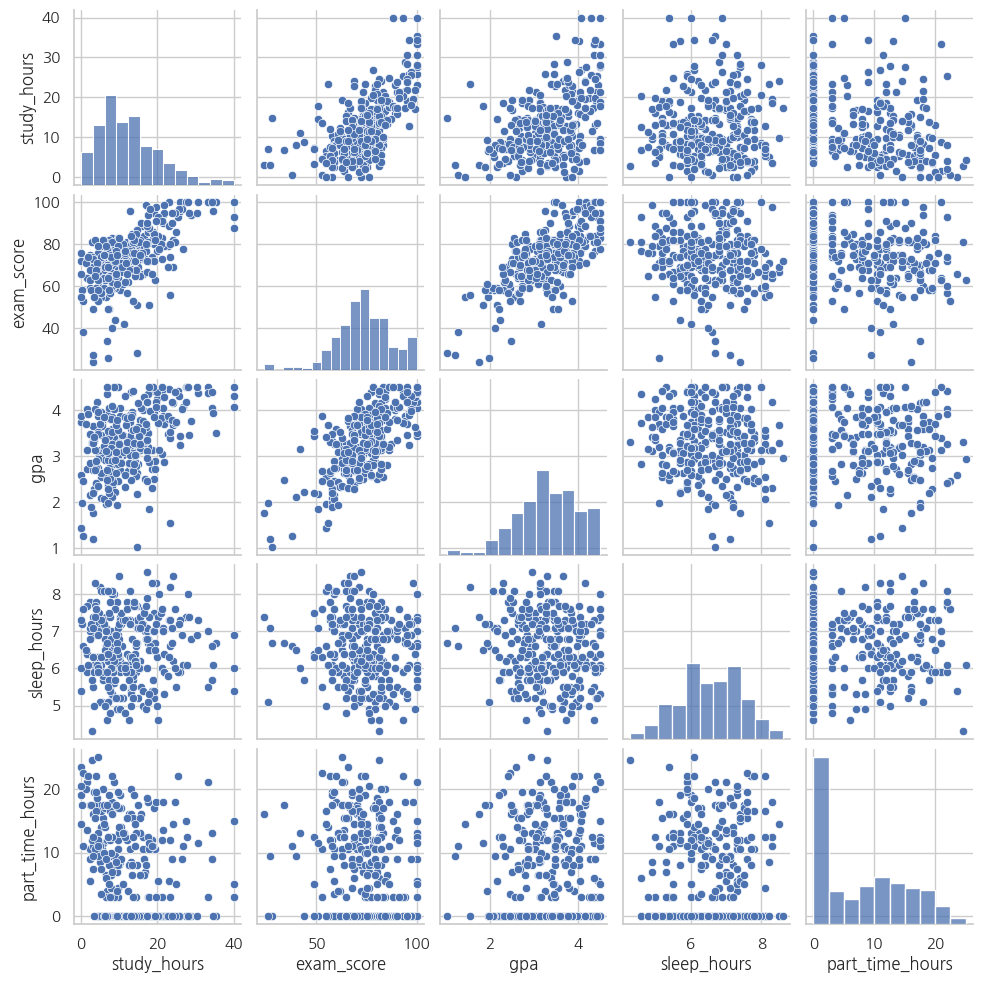

<class 'seaborn.axisgrid.PairGrid'>


In [16]:
# pairplot에 넣을 열 다섯 개
pair_cols = ['study_hours', 'exam_score', 'gpa', 'sleep_hours', 'part_time_hours']

# 다섯 열의 모든 쌍을 격자로 그린다
g = sns.pairplot(students, vars=pair_cols, height=2)
# 그래프를 화면에 보여 준다
plt.show()

# g의 종류를 출력한다
print(type(g))

* 5 × 5 = 25칸이다. 칸의 행이 y축, 열이 x축이다.
  * study_hours·exam_score·gpa 셋이 만나는 칸은 점이 오른쪽 위로 기운다(1)의 진한 빨강 칸).
  * 대각선의 part_time_hours 히스토그램은 0시간 막대가 가장 높다(아르바이트를 하지 않는 학생 112명).
* 대각선 위아래는 x·y만 바뀐 같은 그래프다.
  * <b>corner=True</b>: 아래 삼각형만 그린다. 칸이 15개로 줄어 읽기 쉽다.
* <b>hue='housing'</b>으로 주거 형태마다 색을 나눈다.
  * hue를 주면 대각선은 히스토그램 대신 색마다 밀도 곡선(6차시 kdeplot)을 겹쳐 그린다.
  * <b>plot_kws={'s': 10, 'alpha': 0.5}</b>: 산점도 칸에만 줄 설정을 사전으로 넘긴다(8차시 scatter_kws와 같은 생각).

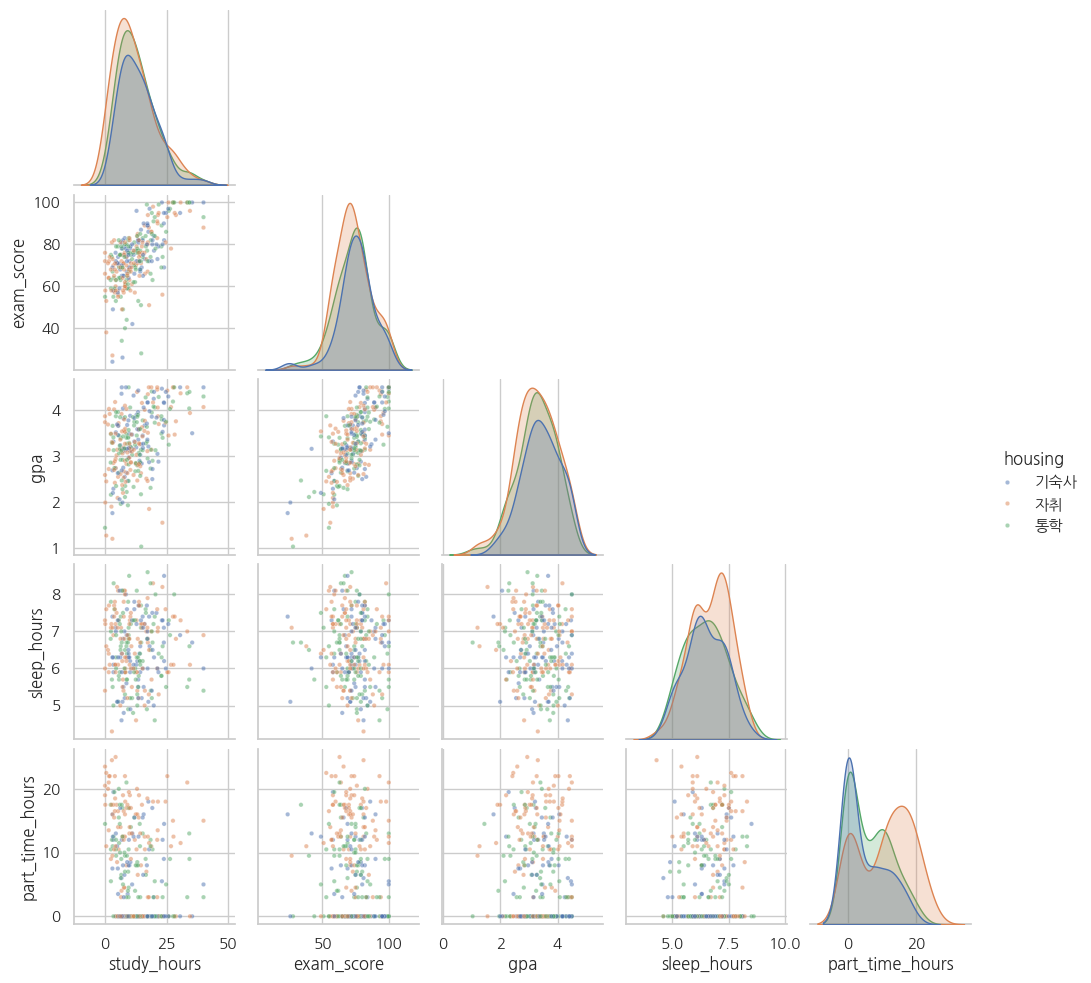

In [17]:
# 주거 형태로 색을 나누고 아래 삼각형만 그린다
g = sns.pairplot(students, vars=pair_cols, hue='housing', corner=True, height=2,
                 plot_kws={'s': 10, 'alpha': 0.5})
# 그래프를 화면에 보여 준다
plt.show()

* 그래프에서 읽을 것
  * 대각선 part_time_hours 곡선: 기숙사·통학 곡선은 0시간 근처 봉우리가 가장 높고, 자취 곡선은 15시간 근처에 가장 높은 봉우리가 있어 오른쪽(긴 아르바이트)으로 퍼져 있다. 주거별 중앙값은 기숙사 0, 통학 5, 자취 12.5시간이다.
  * 다른 대각선 칸(공부 시간·점수·평점·수면)은 세 색 곡선이 거의 겹친다.
  * study_hours-exam_score 칸: 세 색이 섞여 같은 방향으로 기운다. 3)에서 본 것처럼 주거 형태가 이 관계를 가르지 않는다.
* 처음 받은 데이터는 pairplot으로 전체를 훑고, 눈에 띄는 쌍을 골라 8차시의 산점도·회귀선이나 3)의 칸 나누기로 자세히 본다.
* 오늘 정리: <b>heatmap</b>은 표의 칸을 색으로(상관은 발산형, 한 방향 값은 연속형), <b>pivot_table</b>은 두 범주가 만나는 표, <b>relplot·catplot</b>은 같은 그래프를 집단별 칸으로, <b>pairplot</b>은 여러 변수 쌍을 한 장에 보여 준다.